# Federated vs Centralized Machine Learning for Heart Disease Prediction

**Gulam Uddin and Raj Bariya**

This notebook walks through the project from the data loader to the final evaluation:

1. retrieve and audit the four UCI hospital files,
2. split each hospital into training / validation / test partitions,
3. fit the federated preprocessing,
4. define the shared network,
5. run a **small demonstration** of the three approaches on seed 0 (validation data only),
6. load the locked model selection and the **full results** produced by `scripts/run_all.sh`.

The three approaches compared are **centralized training**, **FedAvg** (Flower), and
**FedAvg with local fine-tuning**. Every number shown below is computed from code or read from
saved result files; nothing is typed in by hand. Run `scripts/run_all.sh` first so that the
`results/` folder exists.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from fedheart.utils import environment_info, load_config, results_dir, set_determinism

cfg = load_config()
RESULTS = results_dir(cfg)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
env = environment_info()
print(env["python"].split()[0], env["platform"])
pd.Series(env["key_packages"], name="version").to_frame()

3.12.12 macOS-26.2-arm64-arm-64bit


,version
flwr,1.43.0
torch,2.15.0
scikit-learn,1.9.1
pandas,3.1.1
numpy,2.5.4
scipy,1.18.1
ray,2.55.1
matplotlib,3.11.2


## 1. Data: four real hospitals

The original *processed* files from the UCI repository are used, one file per hospital.
Records are never pooled and re-partitioned into artificial clients. `download_raw` downloads
only missing files and always verifies the SHA-256 digests and record counts recorded in
`configs/default.yaml`.

In [2]:
from fedheart.data import HOSPITALS, build_audit, download_raw, load_dataset

manifest = download_raw(cfg)
pd.DataFrame(manifest["files"]).T[["records", "sha256"]]

,records,sha256
cleveland,303,a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f...
hungary,294,d1ad108f785768cd3d7e82dc522e6f5a61eea93cccfb3a...
switzerland,123,834a405ccf5b66ab4056bb77794adc8df0b7125186454c...
va,200,e7c93d8d0d2acdadfa4c5e8de768e2191e7f618b952e29...


In [3]:
df = load_dataset(cfg)
audit = build_audit(cfg)
cols = ["hospital_label", "n_records", "n_positive", "n_negative", "prevalence",
        "n_extra_duplicate_copies", "fully_missing_predictors"]
audit["hospital_summary"][cols].round(3)

,hospital_label,n_records,n_positive,n_negative,prevalence,n_extra_duplicate_copies,fully_missing_predictors
0,Cleveland,303,139,164,0.459,0,
1,Hungary,294,106,188,0.361,1,
2,Switzerland,123,115,8,0.935,0,chol
3,VA Long Beach,200,149,51,0.745,1,


Percentage of missing values per predictor after cleaning. Missingness is extreme and
hospital-specific: Switzerland never records cholesterol (every value is 0, which rule C2
turns into "missing"), and `ca` is almost never recorded outside Cleveland.

In [4]:
miss = audit["feature_audit"].pivot(index="hospital", columns="feature", values="pct_missing")
miss.loc[list(HOSPITALS)].round(0)

feature,age,ca,chol,cp,exang,fbs,oldpeak,restecg,sex,slope,thal,thalach,trestbps
hospital,,,,,,,,,,,,,
cleveland,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
hungary,0.0,99.0,8.0,0.0,0.0,3.0,0.0,0.0,0.0,65.0,90.0,0.0,0.0
switzerland,0.0,96.0,100.0,0.0,1.0,61.0,5.0,1.0,0.0,14.0,42.0,1.0,2.0
va,0.0,99.0,28.0,0.0,26.0,4.0,28.0,0.0,0.0,51.0,83.0,26.0,28.0


Cleaning rules that changed or flagged records (full rationale in
`docs/CLEANING_DECISIONS.md`; full audit in `docs/DATA_AUDIT.md`):

In [5]:
log = audit["cleaning_log"]
log[(log["n_rows"] > 0) & (log["rule"] != "C6")][["hospital", "rule", "column", "n_rows", "action"]]

,hospital,rule,column,n_rows,action
8,switzerland,C2,chol,123,set to missing
10,switzerland,C4,oldpeak,11,retained
12,va,C2,chol,49,set to missing
13,va,C3,trestbps,1,set to missing
14,va,C4,oldpeak,1,retained


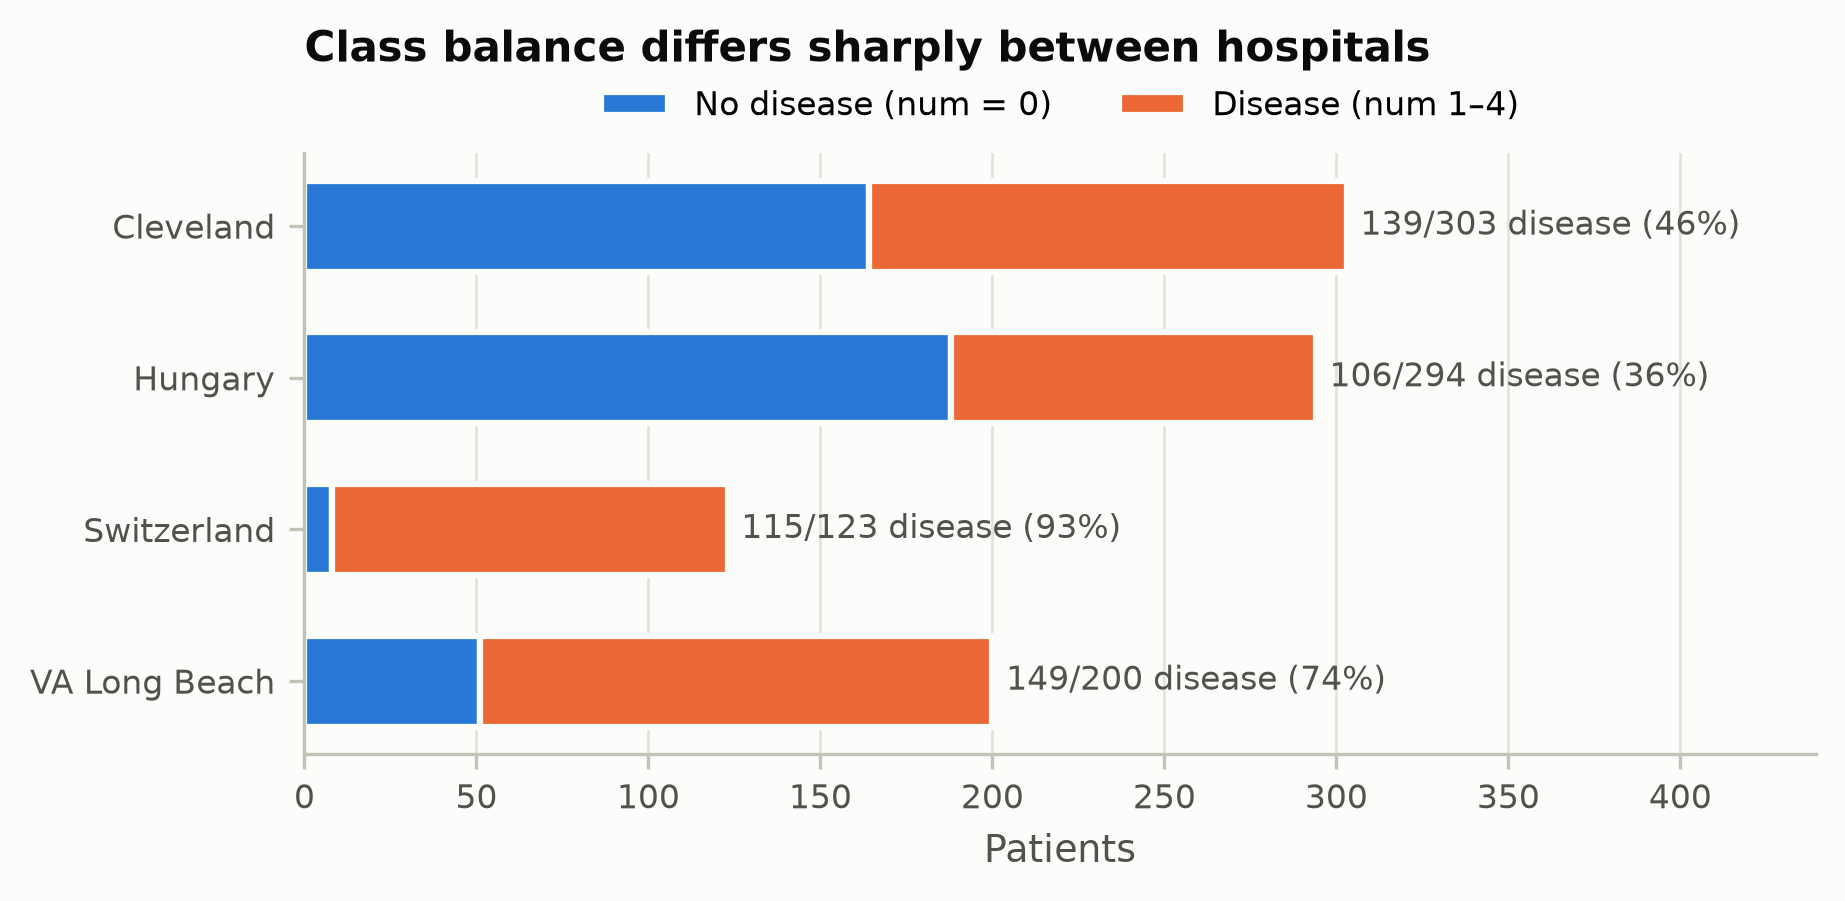

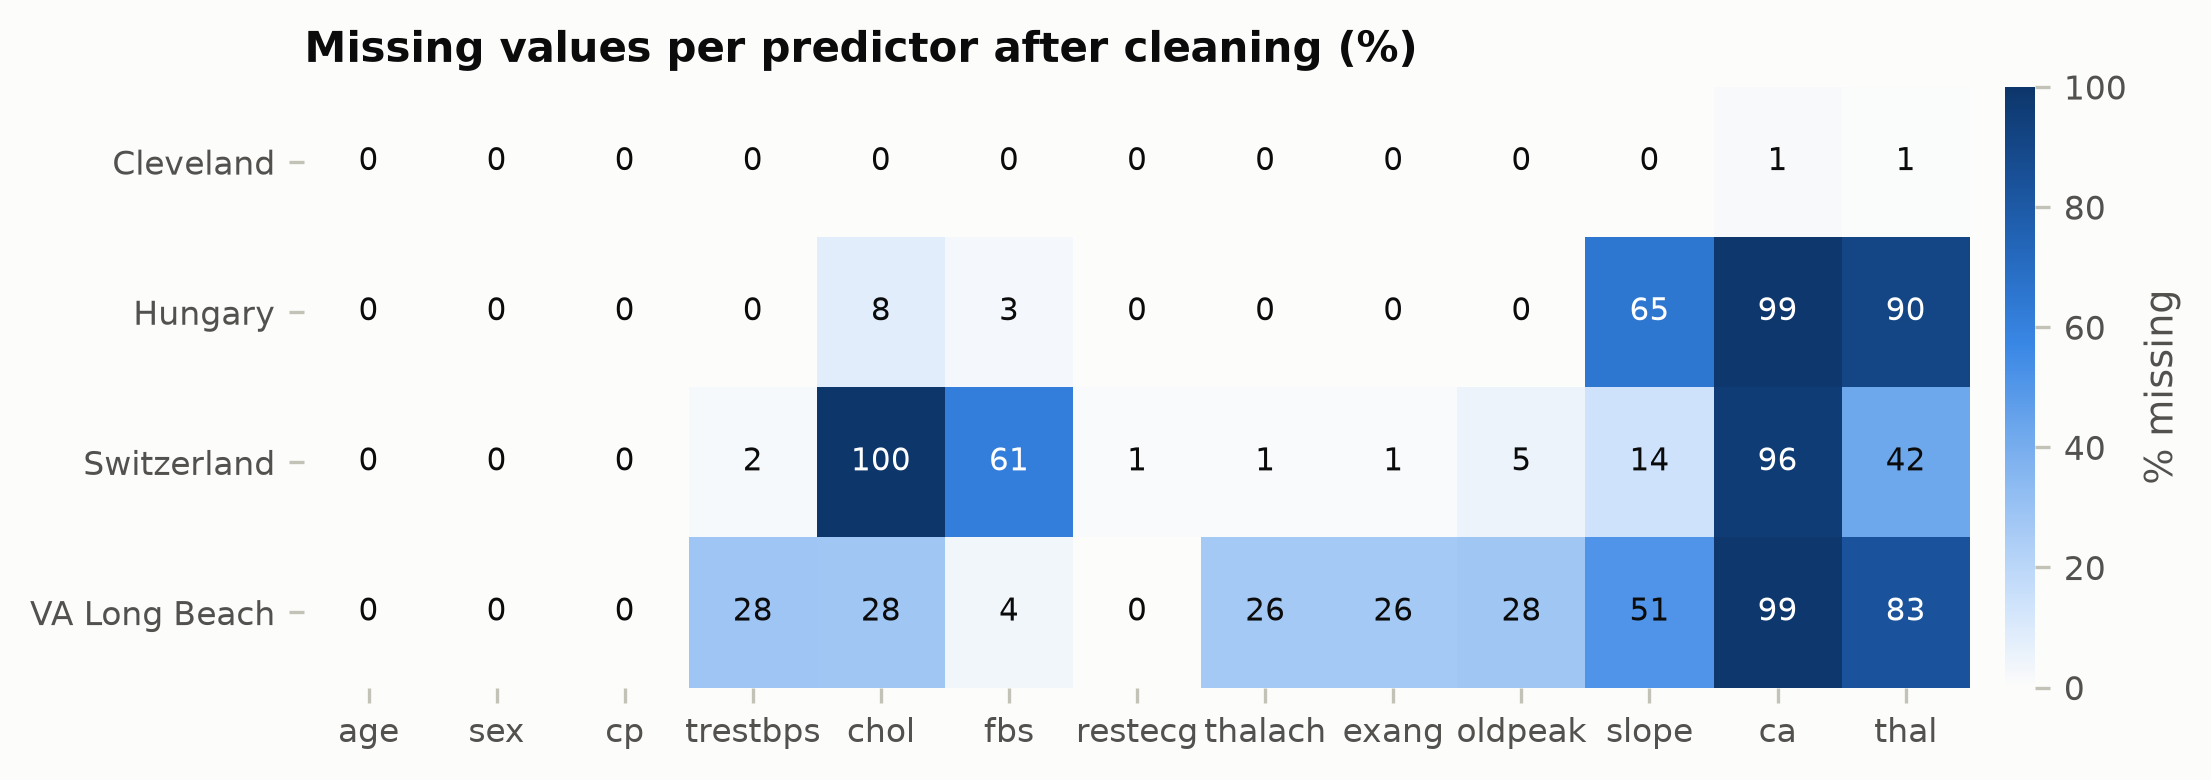

In [6]:
for name in ("fig1_class_balance", "fig2_missingness"):
    path = RESULTS / "figures" / f"{name}.png"
    if path.exists():
        display(Image(str(path), width=760))

## 2. Stratified 60/20/20 splits within each hospital

First check that every hospital's minority class can support the split. Switzerland has only
8 patients without disease, so each of its validation and test partitions will contain just
1–2 of them.

In [7]:
from fedheart.splits import make_split, minority_class_feasibility, split_summary

minority_class_feasibility(df, cfg["split"]["fractions"])

,hospital,n_records,n_positive,n_negative,minority_class,n_minority,expected_minority_train,expected_minority_val,expected_minority_test,feasible
0,cleveland,303,139,164,positive,139,83.4,27.8,27.8,True
1,hungary,294,106,188,positive,106,63.6,21.2,21.2,True
2,switzerland,123,115,8,negative,8,4.8,1.6,1.6,True
3,va,200,149,51,negative,51,30.6,10.2,10.2,True


In [8]:
split0 = make_split(df, 0, cfg["split"]["fractions"])
split_summary(split0, 0).pivot(index="hospital", columns="partition", values=["n", "n_negative"])

n           n_negative          
partition   test train val       test train val
hospital                                       
cleveland     61   181  61         33    98  33
hungary       59   175  60         38   112  38
switzerland   25    73  25          1     5   2
va            40   120  40         11    30  10

Exact duplicate rows share a group id and always land in the same partition:

In [9]:
split0[split0["group_id"].duplicated(keep=False)][["record_id", "group_id", "partition"]]

,record_id,group_id,partition
404,hungary_101,hungary_g101,val
405,hungary_102,hungary_g101,val
859,va_139,va_g139,train
907,va_187,va_g139,train


In [10]:
saved = pd.read_csv(RESULTS / "seeds" / "seed_00" / "split.csv")
same = saved.set_index("record_id")["partition"].sort_index().equals(
    split0.set_index("record_id")["partition"].sort_index())
print("split recreated here is identical to the saved split used by the experiments:", same)

split recreated here is identical to the saved split used by the experiments: True


## 3. Federated preprocessing

Each hospital computes, on its **training partition only**, the count, sum and sum of squares
of every numeric variable and shares just those numbers. The coordinator combines them into a
mean and standard deviation. The categorical encoding is fixed in advance from the UCI
documentation, so it is not learned at all.

In [11]:
from fedheart.data import NUMERIC_FEATURES
from fedheart.prepare import partition_frame
from fedheart.preprocess import FEATURE_NAMES, N_FEATURES, fit_federated

train_frames = {h: partition_frame(df, split0, h, "train") for h in HOSPITALS}
pre, client_stats = fit_federated(train_frames)
pd.DataFrame([{"hospital": s.hospital, "training rows": s.n_rows,
               **{f"observed {c}": s.n_observed[c] for c in NUMERIC_FEATURES}}
              for s in client_stats])

,hospital,training rows,observed age,observed trestbps,observed chol,observed thalach,observed oldpeak
0,cleveland,181,181,181,181,181,181
1,hungary,175,175,175,163,175,175
2,switzerland,73,73,72,0,73,70
3,va,120,120,82,87,86,85


Because sums are additive, the federated statistics equal those of a scaler fitted on the
pooled training rows, so the centralized model can be given exactly the same representation:

In [12]:
from sklearn.preprocessing import StandardScaler

pooled = pd.concat(train_frames.values())
scaler = StandardScaler().fit(pooled[list(NUMERIC_FEATURES)].to_numpy())
pd.DataFrame({
    "federated mean": pre.mean,
    "pooled-fit mean": dict(zip(NUMERIC_FEATURES, scaler.mean_, strict=True)),
    "federated SD": pre.std,
    "pooled-fit SD": dict(zip(NUMERIC_FEATURES, scaler.scale_, strict=True)),
})

,federated mean,pooled-fit mean,federated SD,pooled-fit SD
age,53.856102,53.856102,9.535060,9.535060
trestbps,131.533333,131.533333,17.692966,17.692966
chol,247.178654,247.178654,57.495349,57.495349
thalach,137.182524,137.182524,26.408253,26.408253
oldpeak,0.879843,0.879843,1.069523,1.069523


Every hospital produces the same 41 columns in the same order. Switzerland's cholesterol is
never observed, so it becomes "0 after standardization" with its missing indicator set to 1;
the input dimension does not change.

In [13]:
X_swiss = pre.transform(train_frames["switzerland"])
print("features:", N_FEATURES, "| Switzerland training matrix:", X_swiss.shape)
print(FEATURE_NAMES)
cols = [FEATURE_NAMES.index("chol"), FEATURE_NAMES.index("chol__missing")]
pd.Series(X_swiss[:, cols].mean(0), index=["mean of standardized chol", "mean of chol__missing"])

features: 41 | Switzerland training matrix: (73, 41)
('age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'age__missing', 'trestbps__missing', 'chol__missing', 'thalach__missing', 'oldpeak__missing', 'sex=0', 'sex=1', 'sex=missing', 'cp=1', 'cp=2', 'cp=3', 'cp=4', 'cp=missing', 'fbs=0', 'fbs=1', 'fbs=missing', 'restecg=0', 'restecg=1', 'restecg=2', 'restecg=missing', 'exang=0', 'exang=1', 'exang=missing', 'slope=1', 'slope=2', 'slope=3', 'slope=missing', 'ca=0', 'ca=1', 'ca=2', 'ca=3', 'ca=missing', 'thal=3', 'thal=6', 'thal=7', 'thal=missing')


mean of standardized chol    0.0
mean of chol__missing        1.0
dtype: float32

## 4. The shared network

In [14]:
from fedheart.model import HeartMLP, count_parameters

net = HeartMLP(N_FEATURES, cfg["model"]["hidden_units"])
print(net)
print("parameters:", count_parameters(net))

HeartMLP(
  (hidden): Linear(in_features=41, out_features=16, bias=True)
  (act): ReLU()
  (out): Linear(in_features=16, out_features=1, bias=True)
)
parameters: 689


## 5. Demonstration on seed 0 (validation data only, shortened budgets)

This section shows the three procedures running. It uses **shorter budgets** than the
reported experiments (10 centralized epochs, 5 FedAvg rounds, 3 fine-tuning epochs) and only
training/validation data. **These are not the reported results**; those come from sections
6–8. FedAvg runs in Flower's simulation engine with one client per hospital; it takes about
half a minute, mostly Flower's message polling.

In [15]:
from fedheart.centralized import train_centralized
from fedheart.fedavg_flower import run_fedavg
from fedheart.finetune import finetune_hospital
from fedheart.prepare import load_seed, seed_dir

set_determinism(0)
s0 = load_seed(cfg, 0)
common = {"batch_size": cfg["training"]["batch_size"], "seed": 0,
          "hidden": cfg["model"]["hidden_units"]}
demo_central = train_centralized(s0["arrays"], s0["init"], lr=1e-3, max_epochs=10, **common)
demo_fedavg = run_fedavg(data_dir=seed_dir(cfg, 0) / "client_data", init_state=s0["init"],
                         lr=1e-3, num_rounds=5, local_epochs=1, **common)
demo_ft = {h: finetune_hospital(demo_fedavg["best_state"], s0["arrays"][h], lr=1e-4,
                                max_epochs=3, **common)
           for h in HOSPITALS}


            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        


In [16]:
print("Centralized: pooled validation BCE per epoch")
display(demo_central["history"][["epoch", "train_loss", "val_loss"]].round(4).T)
print("FedAvg (Flower): every round all 4 hospitals replied; aggregation weights = training sizes")
display(demo_fedavg["history"][["round", "train_n_replies", "val_n_replies", "val_loss",
                                *[f"train_n_{h}" for h in HOSPITALS]]].round(4))
print("Local fine-tuning: epoch chosen on each hospital's validation data (0 = FedAvg model)")
pd.DataFrame({h: {"selected epoch": r["best_epoch"],
                  "val BCE at epoch 0": r["history"].loc[0, "val_loss"],
                  "val BCE selected": r["best_val_loss"]}
              for h, r in demo_ft.items()}).T.round(4)

Centralized: pooled validation BCE per epoch


,0,1,2,3,4,5,6,7,8,9,10
epoch,0.0000,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
train_loss,NaN,0.6758,0.6149,0.5562,0.5029,0.4596,0.4295,0.4112,0.3975,0.3889,0.3838
val_loss,0.7102,0.6420,0.5767,0.5129,0.4595,0.4216,0.3979,0.3836,0.3745,0.3700,0.3670


FedAvg (Flower): every round all 4 hospitals replied; aggregation weights = training sizes


,round,train_n_replies,val_n_replies,val_loss,train_n_cleveland,train_n_hungary,train_n_switzerland,train_n_va
0,1,4,4,0.6959,181,175,73,120
1,2,4,4,0.6824,181,175,73,120
2,3,4,4,0.6670,181,175,73,120
3,4,4,4,0.6520,181,175,73,120
4,5,4,4,0.6369,181,175,73,120


Local fine-tuning: epoch chosen on each hospital's validation data (0 = FedAvg model)


,selected epoch,val BCE at epoch 0,val BCE selected
cleveland,3.0,0.6195,0.6134
hungary,3.0,0.6298,0.6230
switzerland,3.0,0.6404,0.6291
va,3.0,0.6717,0.6617


## 6. Locked model selection

Learning rates were chosen on validation data only (four values per method), then the
selection was written to `results/selection.json` and locked with its SHA-256. Test data can
only be loaded after that lock exists, and every access is logged.

In [17]:
from fedheart.testset import read_locked_selection

selection = read_locked_selection(cfg)
print({m: selection[m]["lr"] for m in ("centralized", "fedavg", "fedavg_ft")})
pd.read_csv(RESULTS / "tables" / "table4_model_selection.csv")

{'centralized': 0.003, 'fedavg': 0.01, 'fedavg_ft': 0.001}


,Method,Learning rate,Validation BCE (mean ± SD over seeds),Selected
0,Centralized,0.00030,0.3897 ± 0.0431,NaN
1,Centralized,0.00100,0.3856 ± 0.0463,NaN
2,Centralized,0.00300,0.3856 ± 0.0463,yes
3,Centralized,0.01000,0.3898 ± 0.0461,NaN
4,FedAvg,0.00030,0.5169 ± 0.0320,NaN
5,FedAvg,0.00100,0.4205 ± 0.0436,NaN
6,FedAvg,0.00300,0.4151 ± 0.0453,NaN
7,FedAvg,0.01000,0.4149 ± 0.0434,yes
8,FedAvg with local fine-tuning,0.00003,0.4110 ± 0.0430,NaN
9,FedAvg with local fine-tuning,0.00010,0.4037 ± 0.0426,NaN


In [18]:
pd.read_csv(RESULTS / "tables" / "table5_training_budget.csv").set_index("Method").T

Method,Centralized,FedAvg,FedAvg with local fine-tuning (fine-tuning stage only)
Learning rates tried,4,4,4
Runs (all configs),40,40,160 (10 seeds × 4 hospitals × lr)
Training per run,50 epochs,"50 rounds × 1 local epoch, 4 clients",≤10 epochs per hospital
Optimizer steps per run,1750,1800 (all clients),360 (4 hospitals)
Examples processed per run,27475,27475,5495
"Selected epoch/round, median [range]",8 [3–26],8 [3–18],10 [0–10]
Model transfer per run (MB),0 (data pooled),1.65,0 (local only)


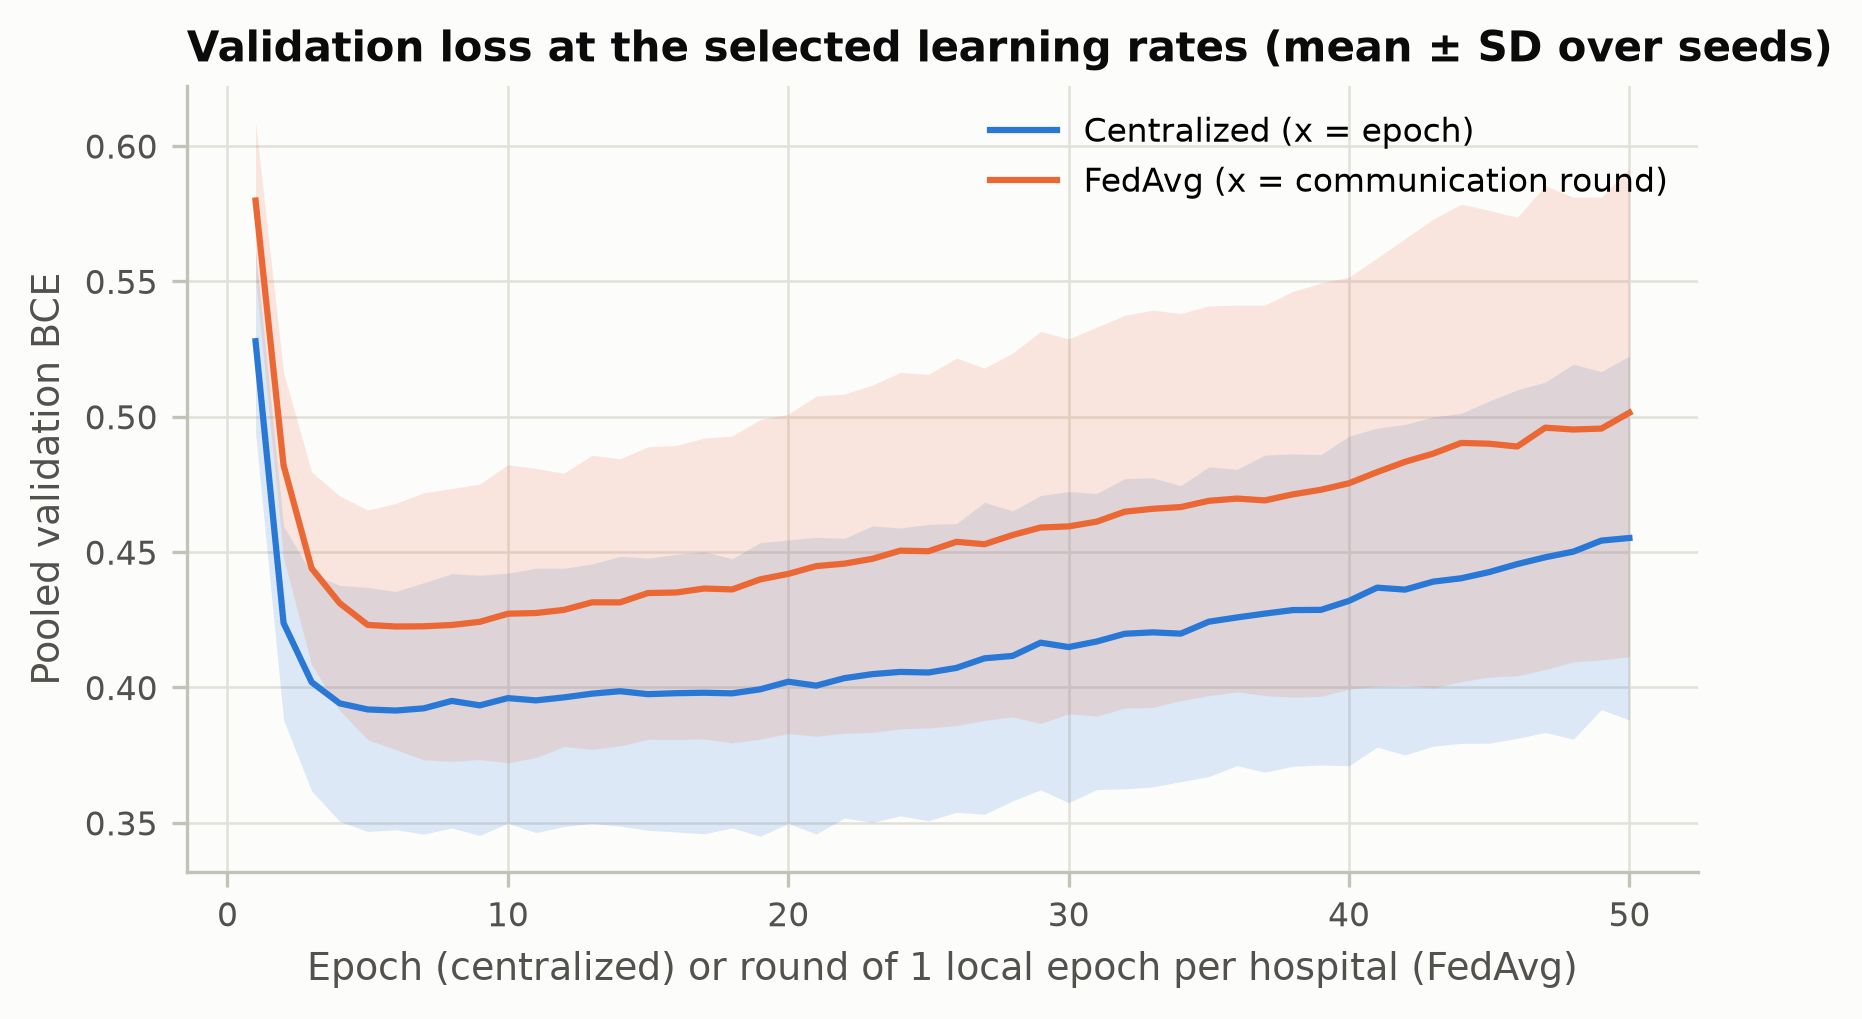

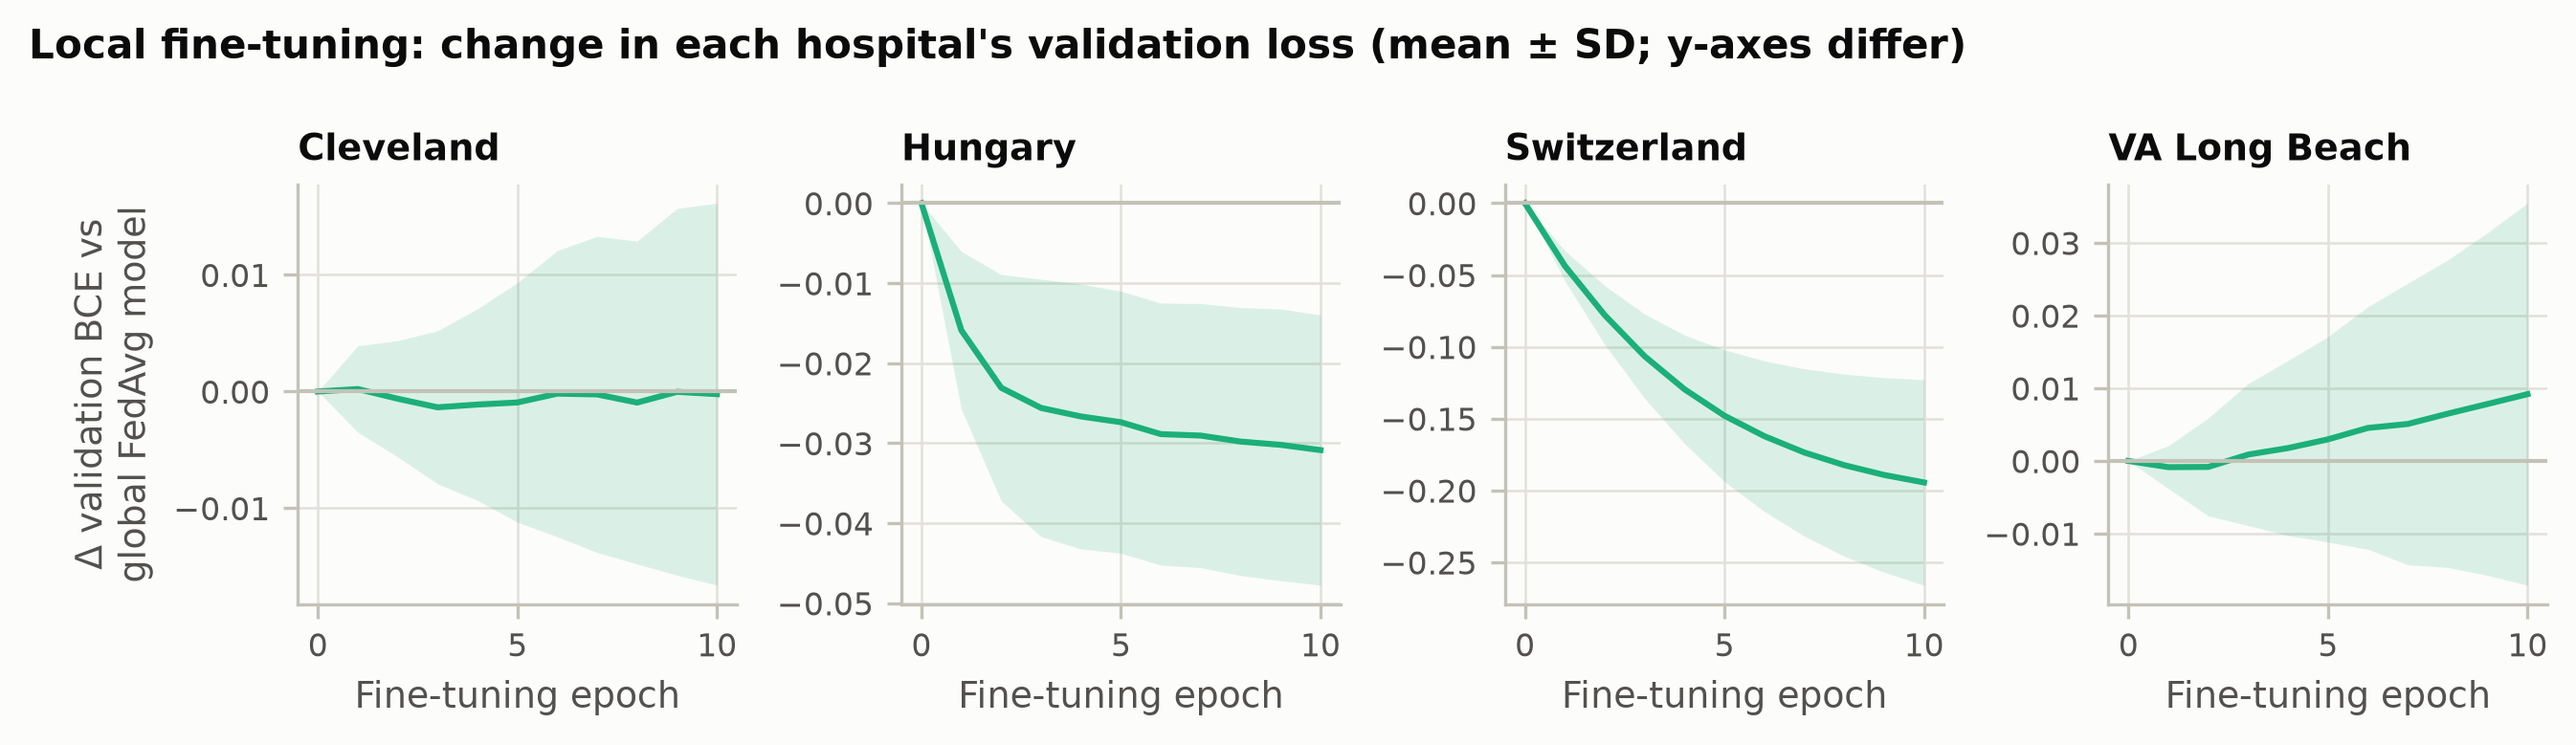

,Hospital,Seeds,Kept global model (epoch 0),"Selected epoch, median [range]"
0,Cleveland,10,3,4 [0–10]
1,Hungary,10,0,10 [3–10]
2,Switzerland,10,0,10 [10–10]
3,VA Long Beach,10,2,6 [0–10]


In [19]:
display(Image(str(RESULTS / "figures" / "fig3_validation_curves.png"), width=700))
display(Image(str(RESULTS / "figures" / "fig4_finetune_curves.png"), width=900))
pd.read_csv(RESULTS / "tables" / "table6_finetune_epochs.csv")

## 7. Test results (10 paired seeds)

*Pooled* = all test patients of all hospitals together (dominated by the two larger
hospitals). *Equal-hospital mean* = unweighted average of the four hospitals. Values are
mean ± SD over seeds; `n/a` marks undefined metrics, which are never replaced by 0.

In [20]:
t2 = pd.read_csv(RESULTS / "tables" / "table2_test_results.csv")
t2[t2["Scope"].isin(["Pooled", "Equal-hospital mean"])]

,Scope,Method,Accuracy,Precision,Recall,F1-score,ROC-AUC
12,Pooled,Centralized,0.821 ± 0.027,0.845 ± 0.026,0.832 ± 0.059,0.837 ± 0.029,0.898 ± 0.019
13,Pooled,FedAvg,0.818 ± 0.021,0.841 ± 0.036,0.833 ± 0.049,0.835 ± 0.021,0.887 ± 0.022
14,Pooled,FedAvg with local fine-tuning,0.837 ± 0.029,0.857 ± 0.030,0.849 ± 0.046,0.852 ± 0.028,0.904 ± 0.021
15,Equal-hospital mean,Centralized,0.827 ± 0.021,0.848 ± 0.025,0.830 ± 0.063,0.835 ± 0.034,0.837 ± 0.043
16,Equal-hospital mean,FedAvg,0.811 ± 0.020,0.848 ± 0.033,0.828 ± 0.052,0.834 ± 0.022,0.839 ± 0.047
17,Equal-hospital mean,FedAvg with local fine-tuning,0.845 ± 0.026,0.861 ± 0.032,0.845 ± 0.048,0.849 ± 0.031,0.843 ± 0.045


In [21]:
t2[~t2["Scope"].isin(["Pooled", "Equal-hospital mean"])]

,Scope,Method,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Cleveland,Centralized,0.846 ± 0.048,0.842 ± 0.064,0.825 ± 0.106,0.828 ± 0.064,0.914 ± 0.024
1,Cleveland,FedAvg,0.849 ± 0.041,0.840 ± 0.067,0.839 ± 0.072,0.836 ± 0.044,0.910 ± 0.028
2,Cleveland,FedAvg with local fine-tuning,0.848 ± 0.048,0.848 ± 0.073,0.825 ± 0.096,0.831 ± 0.057,0.911 ± 0.029
3,Hungary,Centralized,0.824 ± 0.052,0.785 ± 0.067,0.717 ± 0.122,0.744 ± 0.087,0.895 ± 0.039
4,Hungary,FedAvg,0.834 ± 0.043,0.775 ± 0.071,0.782 ± 0.104,0.774 ± 0.060,0.896 ± 0.048
5,Hungary,FedAvg with local fine-tuning,0.834 ± 0.047,0.828 ± 0.078,0.695 ± 0.093,0.752 ± 0.073,0.902 ± 0.047
6,Switzerland,Centralized,0.912 ± 0.041,0.958 ± 0.034,0.949 ± 0.047,0.952 ± 0.023,0.820 ± 0.166
7,Switzerland,FedAvg,0.800 ± 0.082,0.964 ± 0.034,0.816 ± 0.080,0.882 ± 0.053,0.822 ± 0.154
8,Switzerland,FedAvg with local fine-tuning,0.932 ± 0.027,0.955 ± 0.035,0.975 ± 0.022,0.964 ± 0.014,0.833 ± 0.151
9,VA Long Beach,Centralized,0.725 ± 0.051,0.805 ± 0.033,0.829 ± 0.075,0.815 ± 0.039,0.718 ± 0.079


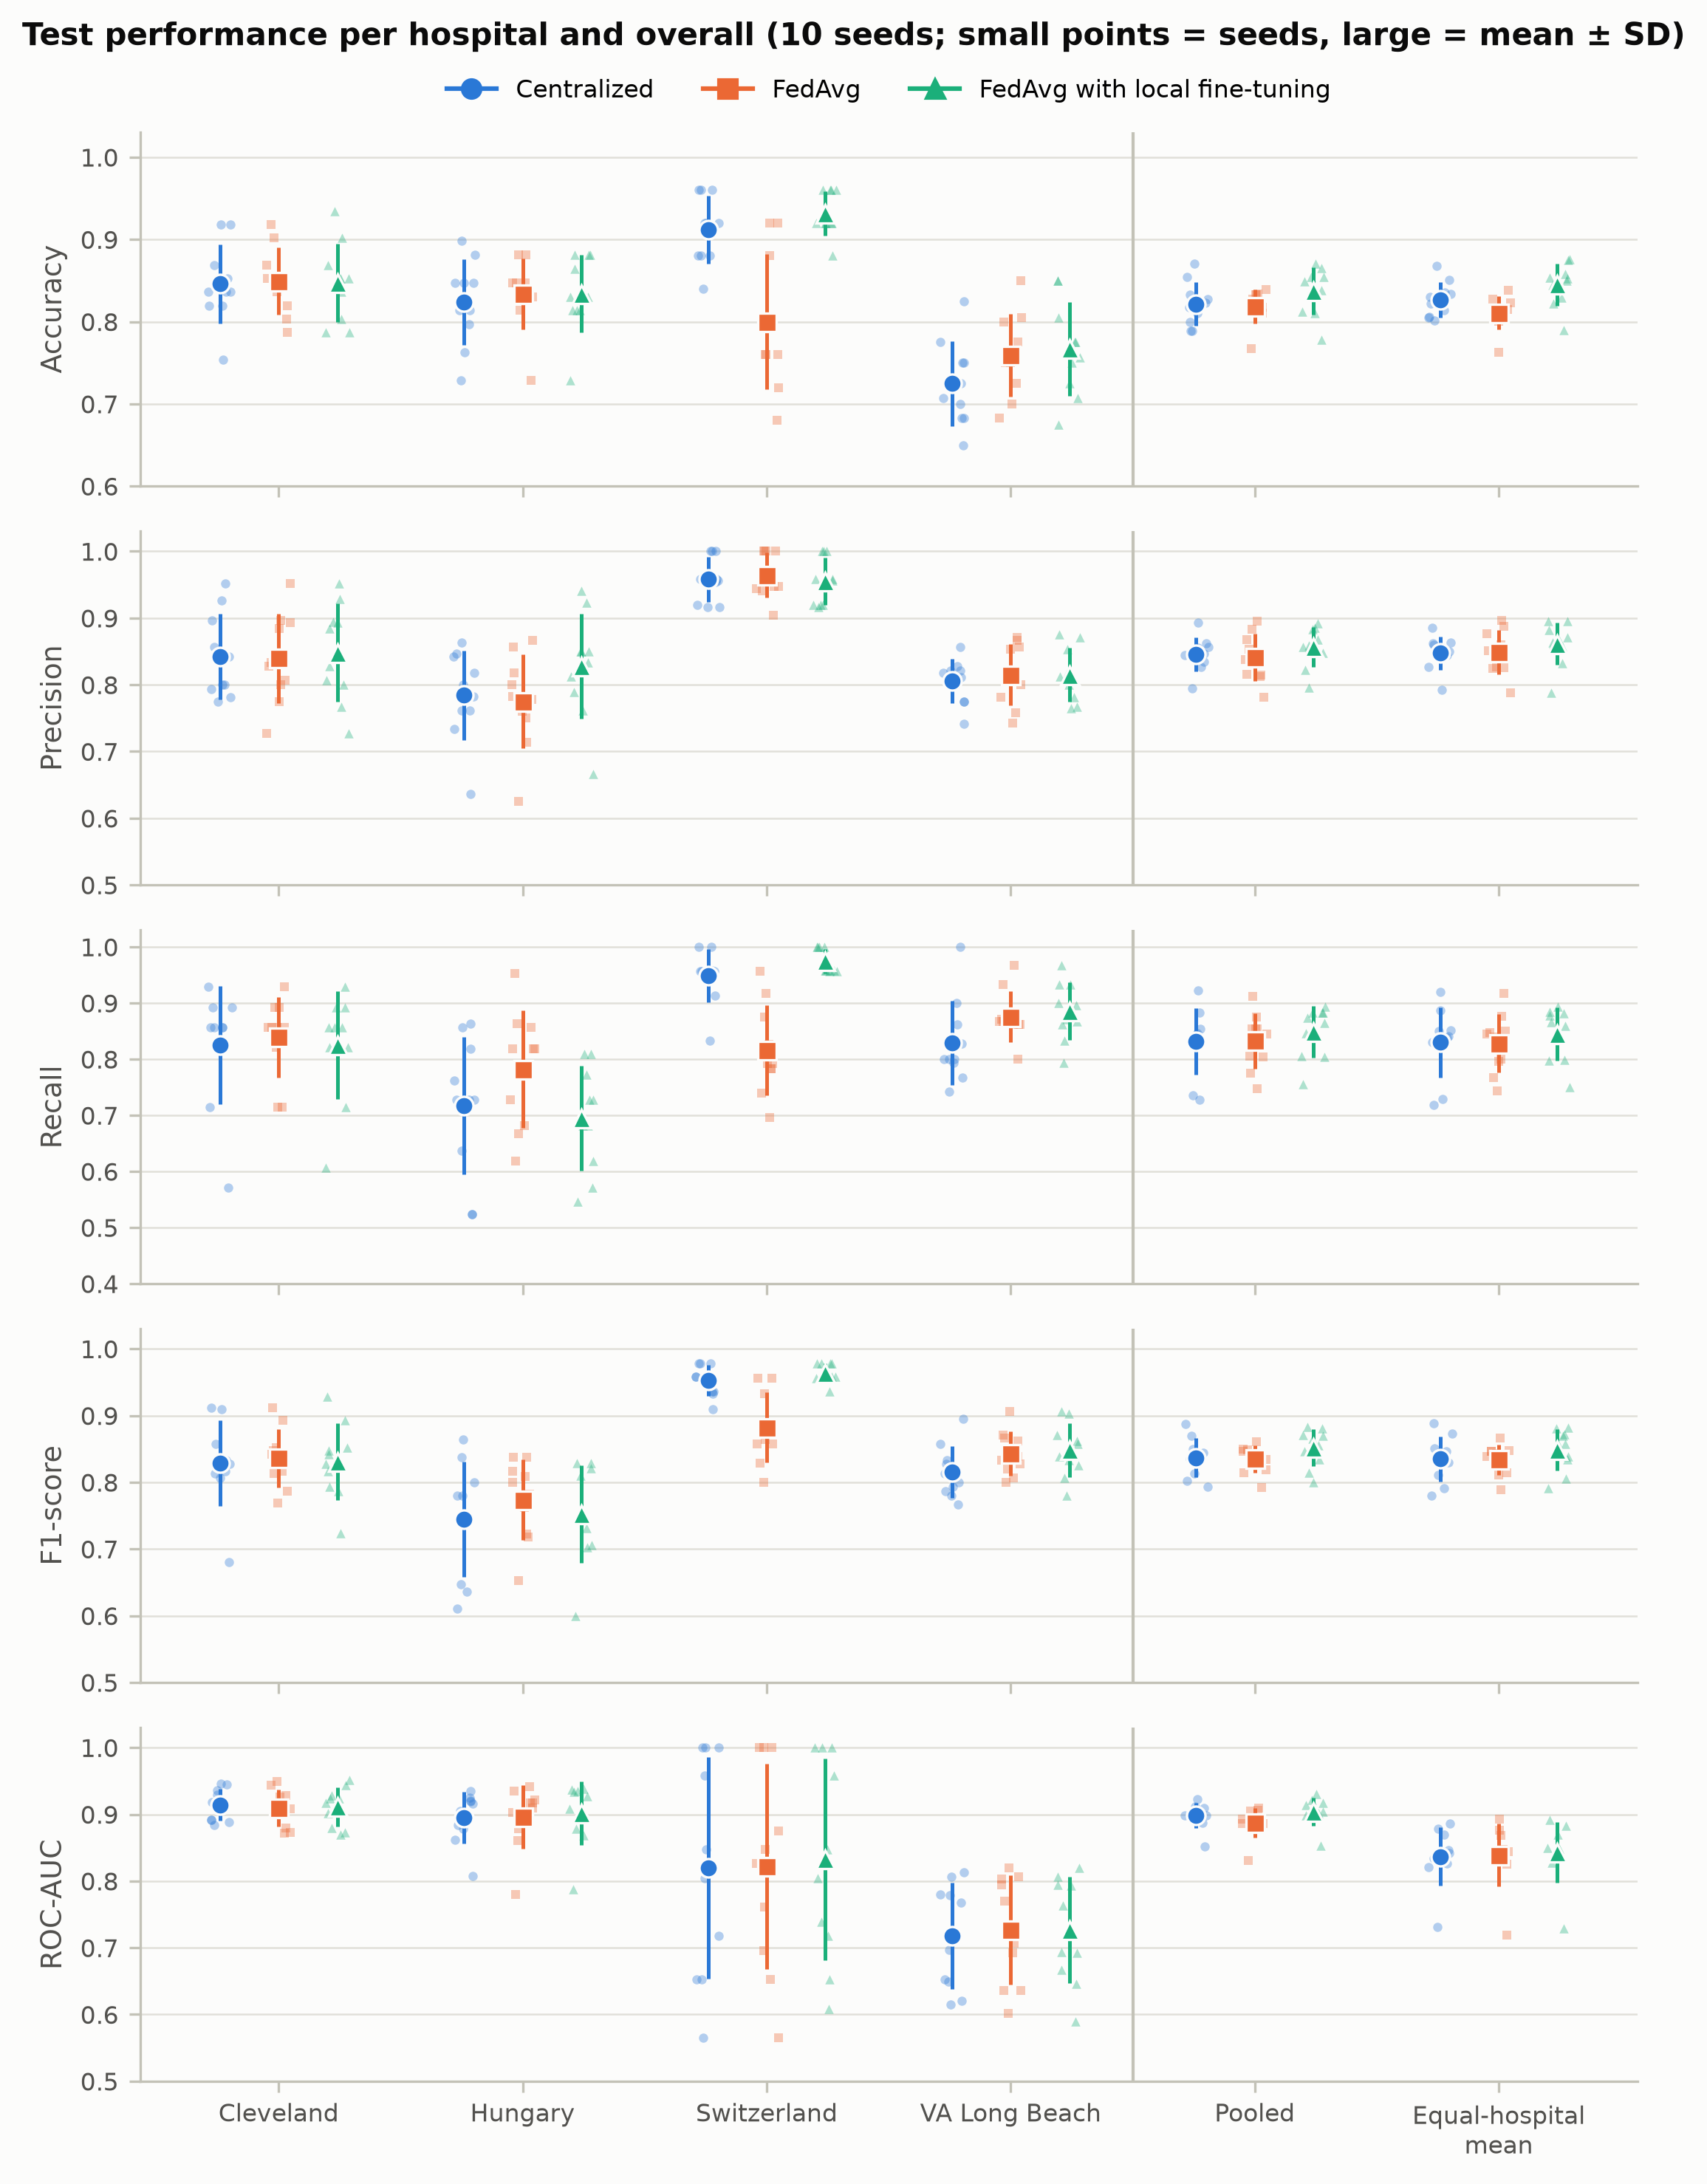

In [22]:
display(Image(str(RESULTS / "figures" / "fig5_test_metrics.png"), width=800))

Paired differences between methods (same seed = same patients and initial weights):

In [23]:
pd.read_csv(RESULTS / "tables" / "table3_paired_differences.csv")

,Scope,Comparison,Accuracy,F1-score,ROC-AUC
0,Cleveland,FedAvg with local fine-tuning − FedAvg,"-0.002 [-0.008, +0.005] (1/2/7)","-0.005 [-0.017, +0.007] (1/2/7)","+0.002 [-0.001, +0.005] (4/2/4)"
1,Cleveland,FedAvg − Centralized,"+0.003 [-0.012, +0.019] (3/2/5)","+0.008 [-0.015, +0.030] (4/3/3)","-0.005 [-0.010, +0.001] (3/7/0)"
2,Cleveland,FedAvg with local fine-tuning − Centralized,"+0.002 [-0.012, +0.016] (4/3/3)","+0.003 [-0.012, +0.017] (4/4/2)","-0.003 [-0.010, +0.004] (3/7/0)"
3,Hungary,FedAvg with local fine-tuning − FedAvg,"+0.000 [-0.015, +0.015] (2/3/5)","-0.021 [-0.042, -0.000] (2/8/0)","+0.005 [+0.000, +0.010] (6/3/1)"
4,Hungary,FedAvg − Centralized,"+0.010 [-0.008, +0.028] (5/2/3)","+0.029 [-0.000, +0.059] (8/2/0)","+0.001 [-0.008, +0.011] (5/4/1)"
5,Hungary,FedAvg with local fine-tuning − Centralized,"+0.010 [-0.011, +0.031] (5/2/3)","+0.008 [-0.029, +0.045] (5/4/1)","+0.006 [-0.002, +0.015] (8/2/0)"
6,Switzerland,FedAvg with local fine-tuning − FedAvg,"+0.132 [+0.073, +0.191] (9/0/1)","+0.082 [+0.044, +0.119] (10/0/0)","+0.011 [-0.012, +0.033] (3/2/5)"
7,Switzerland,FedAvg − Centralized,"-0.112 [-0.167, -0.057] (0/9/1)","-0.070 [-0.106, -0.035] (0/10/0)","+0.003 [-0.033, +0.038] (2/2/6)"
8,Switzerland,FedAvg with local fine-tuning − Centralized,"+0.020 [-0.011, +0.051] (4/1/5)","+0.012 [-0.006, +0.029] (4/1/5)","+0.013 [-0.017, +0.043] (3/1/6)"
9,VA Long Beach,FedAvg with local fine-tuning − FedAvg,"+0.007 [-0.011, +0.026] (4/1/5)","+0.005 [-0.010, +0.020] (4/1/5)","-0.000 [-0.009, +0.009] (2/4/4)"


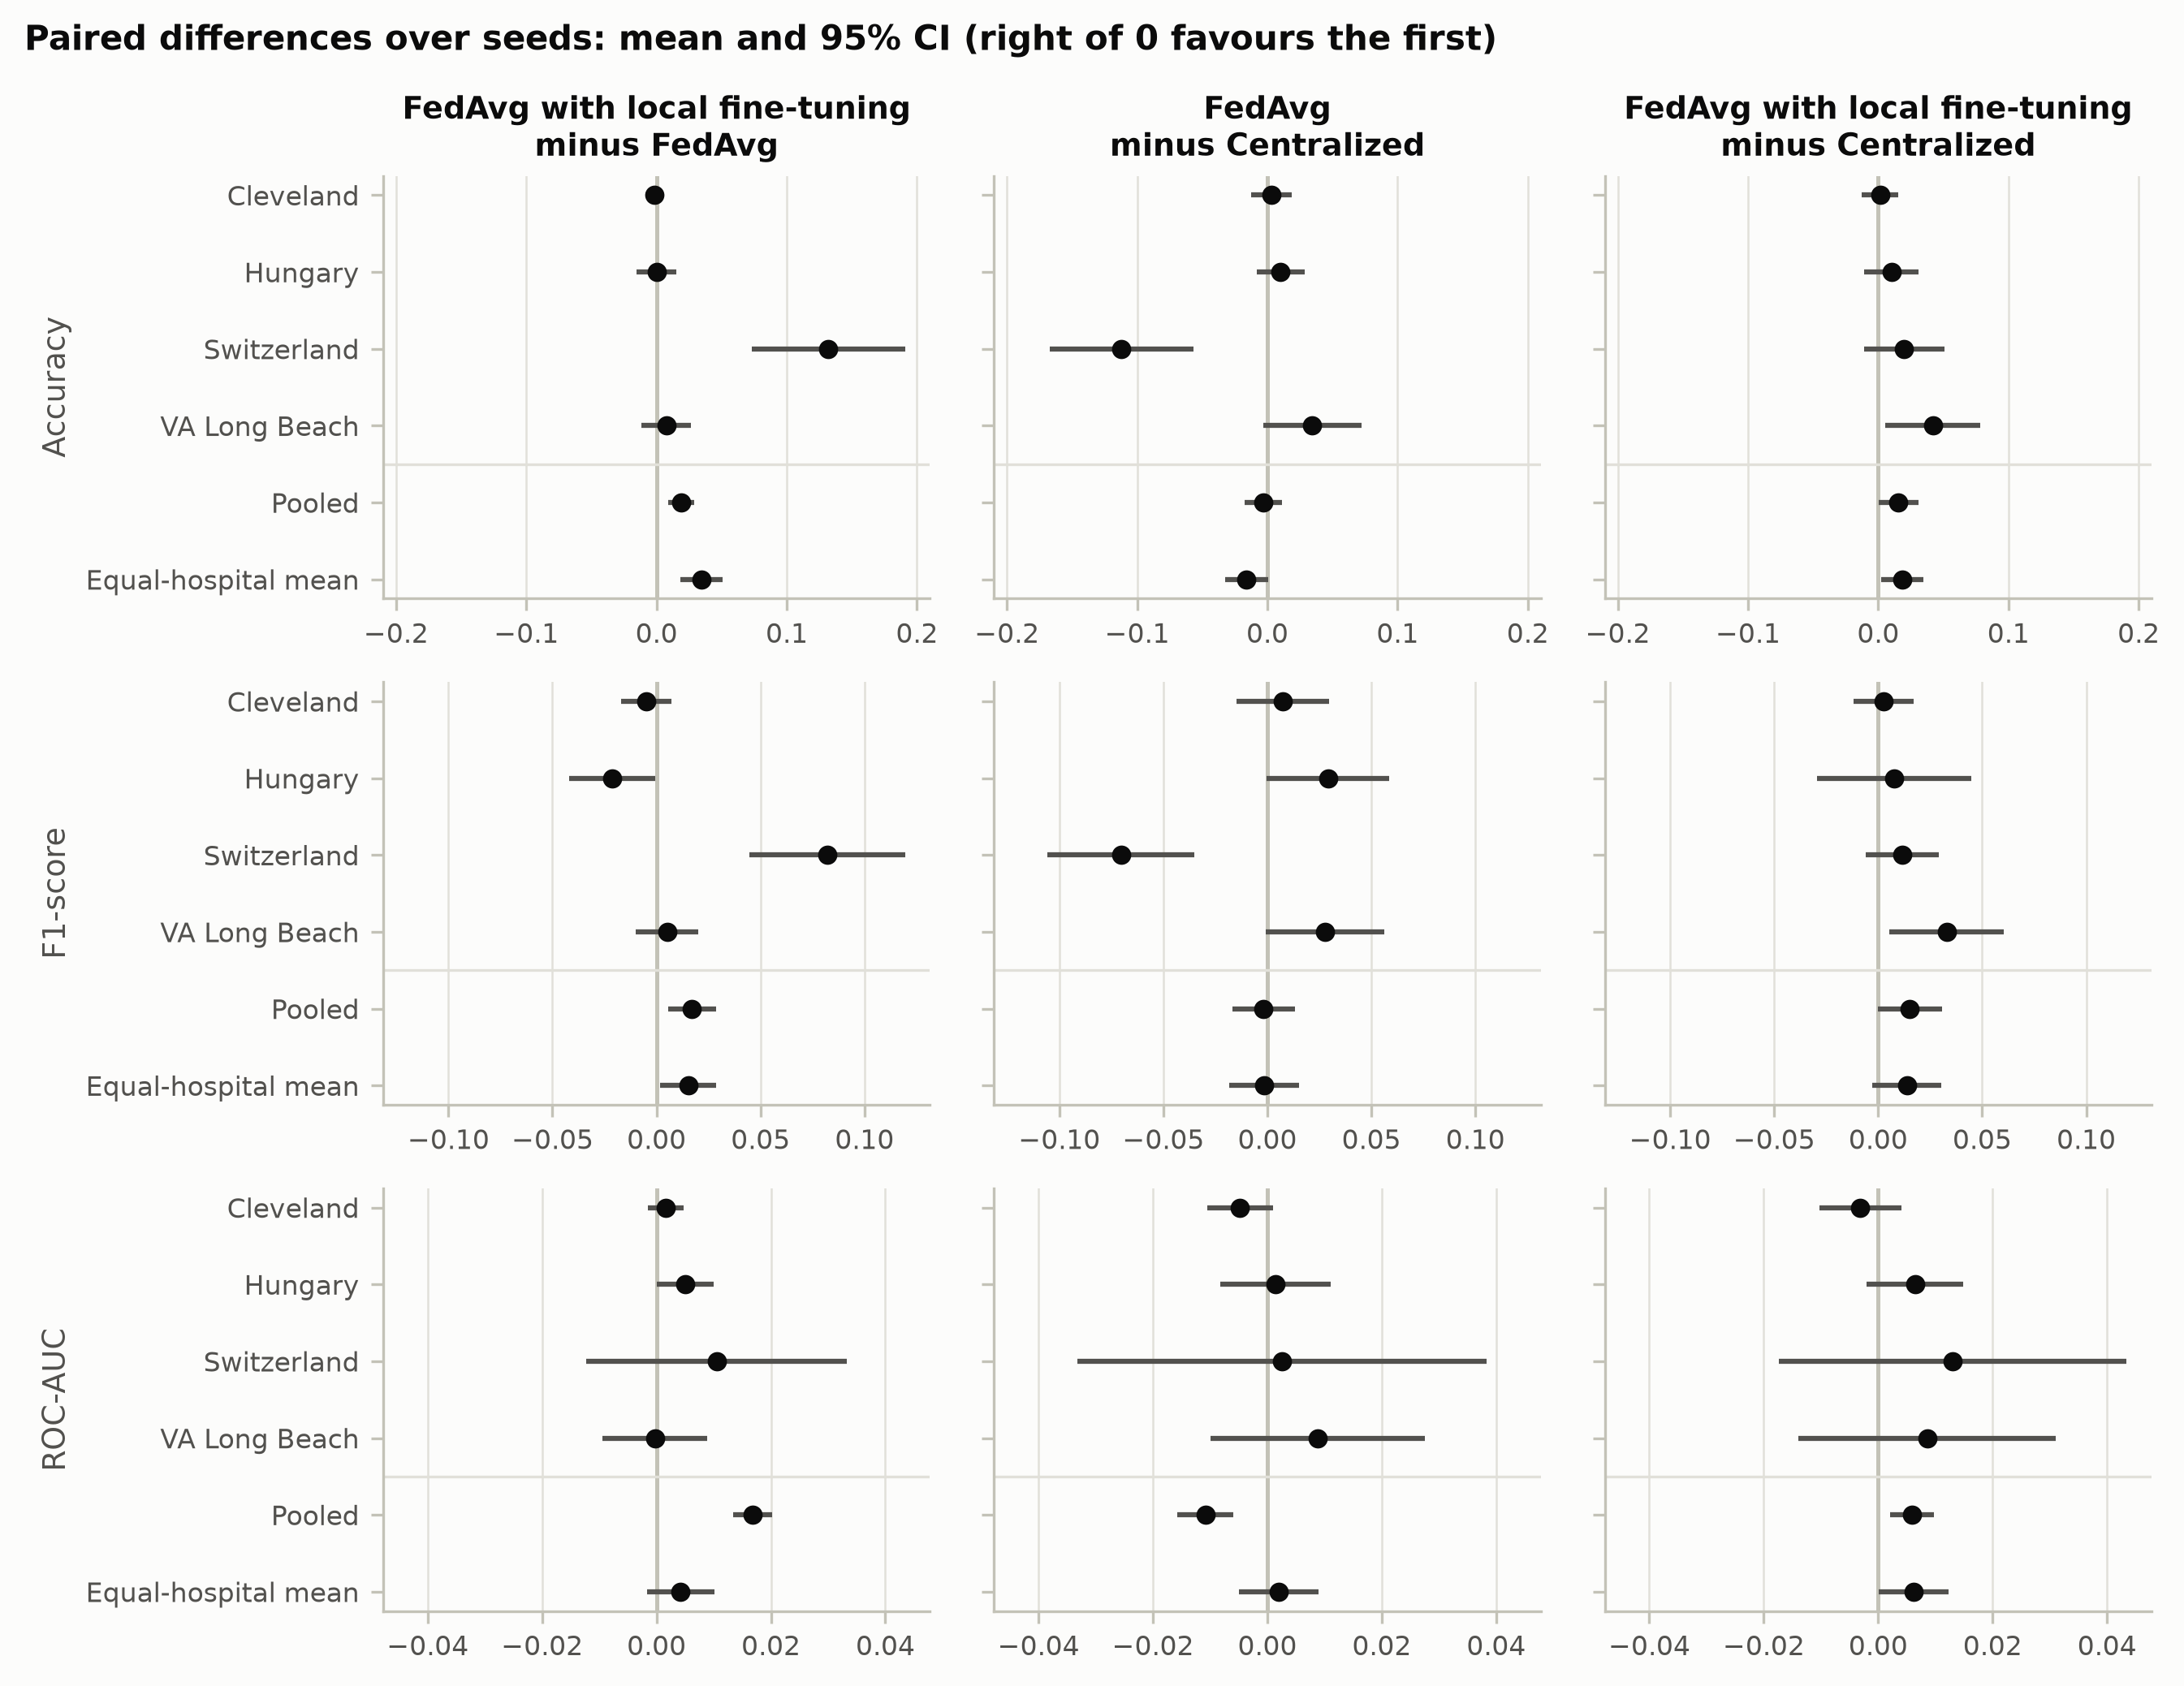

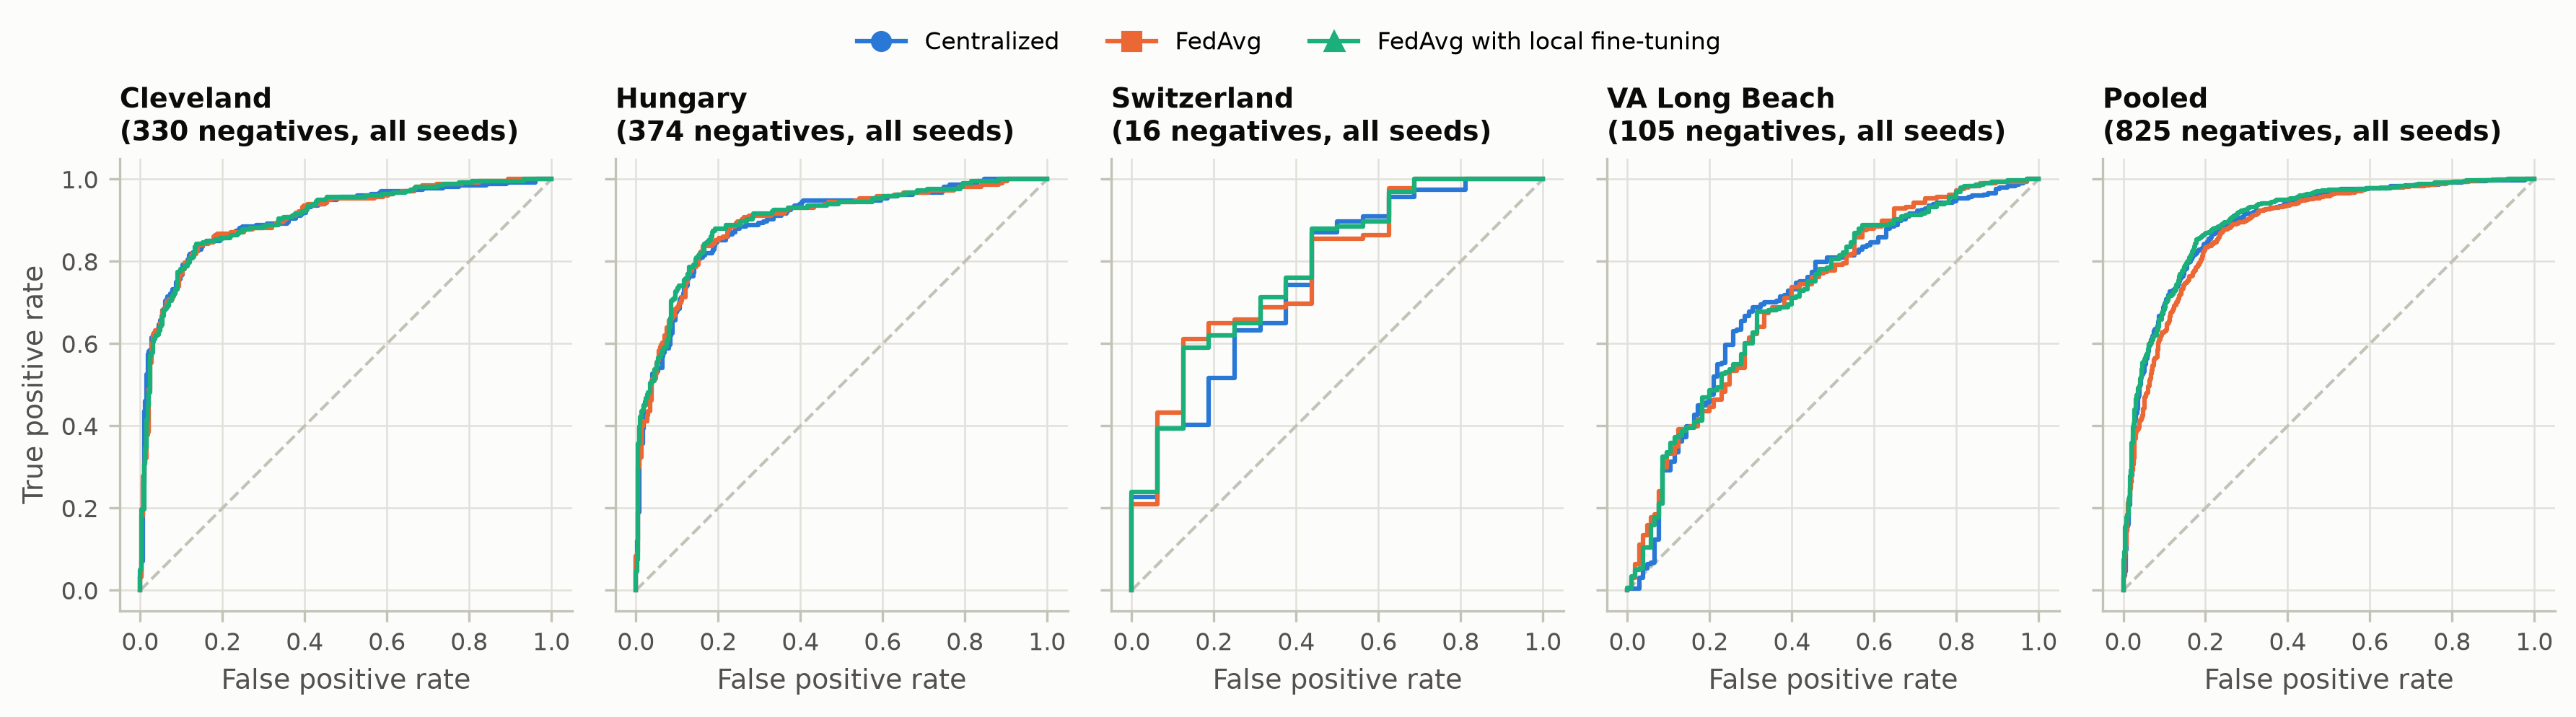

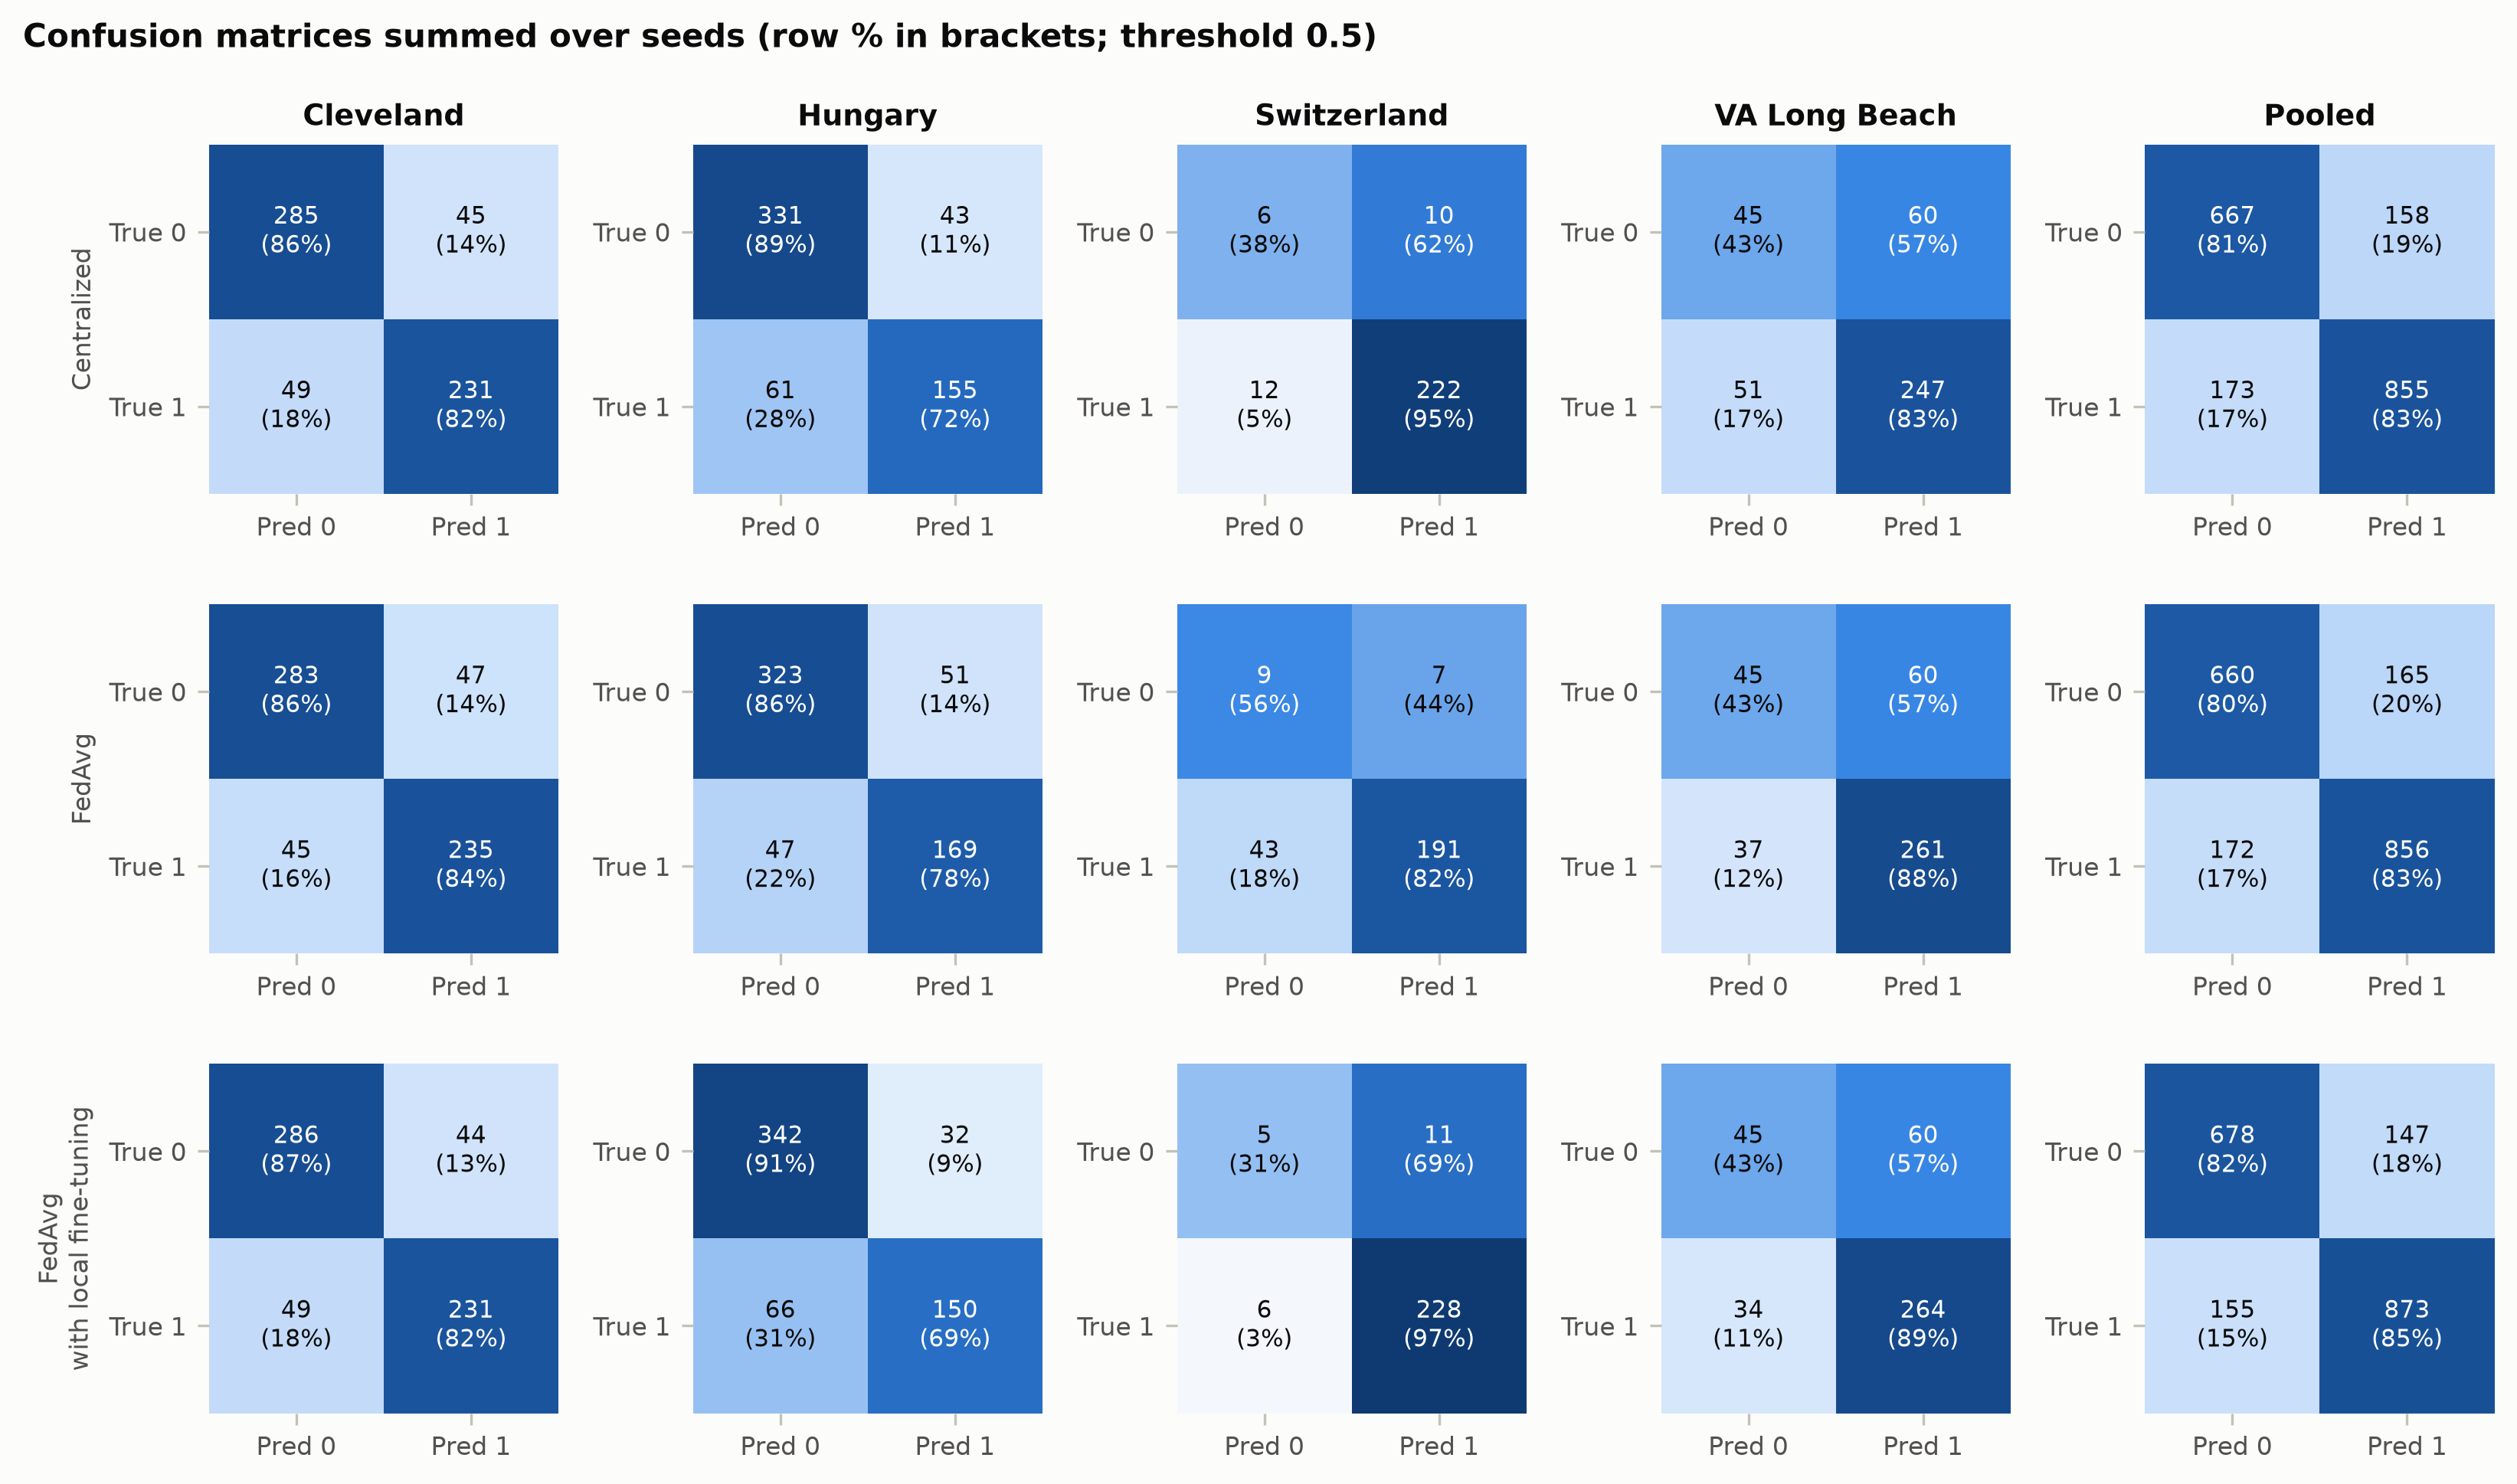

In [24]:
display(Image(str(RESULTS / "figures" / "fig6_paired_differences.png"), width=900))
display(Image(str(RESULTS / "figures" / "fig7_roc_curves.png"), width=1000))
display(Image(str(RESULTS / "figures" / "fig8_confusion_matrices.png"), width=1000))

In [25]:
undefined = pd.read_csv(RESULTS / "tables" / "table8_undefined_metrics.csv")
undefined if len(undefined) else print("No metric was undefined in any seed.")

No metric was undefined in any seed.


## 8. Answers computed from the results

The sentences below are generated from `results/test/paired_differences.csv`. A difference
is "first method minus second method" averaged over seeds, with a 95% t-interval over the 10
seeds and the number of seeds in which the first method was higher, lower or tied.

In [26]:
from fedheart.metrics import METHOD_LABELS
from fedheart.report import METRIC_LABELS, SCOPE_LABELS

pdiff = pd.read_csv(RESULTS / "test" / "paired_differences.csv")


def sentence(scope, metric, a, b):
    r = pdiff[(pdiff.scope == scope) & (pdiff.metric == metric)
              & (pdiff.a == a) & (pdiff.b == b)].iloc[0]
    if pd.isna(r.mean_diff):
        return f"- {SCOPE_LABELS[scope]}, {METRIC_LABELS[metric]}: undefined"
    return (f"- {SCOPE_LABELS[scope]}, {METRIC_LABELS[metric]}: {r.mean_diff:+.3f} "
            f"(95% CI {r.ci95_low:+.3f} to {r.ci95_high:+.3f}; "
            f"seeds higher/lower/tied: {r.wins}/{r.losses}/{r.ties})")


lines = []
for a, b in (("fedavg_ft", "fedavg"), ("fedavg", "centralized"), ("fedavg_ft", "centralized")):
    lines.append(f"**{METHOD_LABELS[a]} minus {METHOD_LABELS[b]}**")
    lines.append("")
    for scope in ("pooled", "equal_hospital_mean", *HOSPITALS):
        for metric in ("f1", "roc_auc"):
            lines.append(sentence(scope, metric, a, b))
    lines.append("")
display(Markdown("\n".join(lines)))

**FedAvg with local fine-tuning minus FedAvg**

- Pooled, F1-score: +0.017 (95% CI +0.005 to +0.029; seeds higher/lower/tied: 8/2/0)
- Pooled, ROC-AUC: +0.017 (95% CI +0.013 to +0.020; seeds higher/lower/tied: 10/0/0)
- Equal-hospital mean, F1-score: +0.015 (95% CI +0.002 to +0.029; seeds higher/lower/tied: 8/2/0)
- Equal-hospital mean, ROC-AUC: +0.004 (95% CI -0.002 to +0.010; seeds higher/lower/tied: 7/3/0)
- Cleveland, F1-score: -0.005 (95% CI -0.017 to +0.007; seeds higher/lower/tied: 1/2/7)
- Cleveland, ROC-AUC: +0.002 (95% CI -0.001 to +0.005; seeds higher/lower/tied: 4/2/4)
- Hungary, F1-score: -0.021 (95% CI -0.042 to -0.000; seeds higher/lower/tied: 2/8/0)
- Hungary, ROC-AUC: +0.005 (95% CI +0.000 to +0.010; seeds higher/lower/tied: 6/3/1)
- Switzerland, F1-score: +0.082 (95% CI +0.044 to +0.119; seeds higher/lower/tied: 10/0/0)
- Switzerland, ROC-AUC: +0.011 (95% CI -0.012 to +0.033; seeds higher/lower/tied: 3/2/5)
- VA Long Beach, F1-score: +0.005 (95% CI -0.010 to +0.020; seeds higher/lower/tied: 4/1/5)
- VA Long Beach, ROC-AUC: -0.000 (95% CI -0.009 to +0.009; seeds higher/lower/tied: 2/4/4)

**FedAvg minus Centralized**

- Pooled, F1-score: -0.002 (95% CI -0.017 to +0.013; seeds higher/lower/tied: 5/5/0)
- Pooled, ROC-AUC: -0.011 (95% CI -0.016 to -0.006; seeds higher/lower/tied: 0/9/1)
- Equal-hospital mean, F1-score: -0.001 (95% CI -0.018 to +0.015; seeds higher/lower/tied: 5/5/0)
- Equal-hospital mean, ROC-AUC: +0.002 (95% CI -0.005 to +0.009; seeds higher/lower/tied: 6/4/0)
- Cleveland, F1-score: +0.008 (95% CI -0.015 to +0.030; seeds higher/lower/tied: 4/3/3)
- Cleveland, ROC-AUC: -0.005 (95% CI -0.010 to +0.001; seeds higher/lower/tied: 3/7/0)
- Hungary, F1-score: +0.029 (95% CI -0.000 to +0.059; seeds higher/lower/tied: 8/2/0)
- Hungary, ROC-AUC: +0.001 (95% CI -0.008 to +0.011; seeds higher/lower/tied: 5/4/1)
- Switzerland, F1-score: -0.070 (95% CI -0.106 to -0.035; seeds higher/lower/tied: 0/10/0)
- Switzerland, ROC-AUC: +0.003 (95% CI -0.033 to +0.038; seeds higher/lower/tied: 2/2/6)
- VA Long Beach, F1-score: +0.028 (95% CI -0.001 to +0.056; seeds higher/lower/tied: 7/1/2)
- VA Long Beach, ROC-AUC: +0.009 (95% CI -0.010 to +0.028; seeds higher/lower/tied: 7/3/0)

**FedAvg with local fine-tuning minus Centralized**

- Pooled, F1-score: +0.015 (95% CI -0.000 to +0.031; seeds higher/lower/tied: 6/3/1)
- Pooled, ROC-AUC: +0.006 (95% CI +0.002 to +0.010; seeds higher/lower/tied: 10/0/0)
- Equal-hospital mean, F1-score: +0.014 (95% CI -0.003 to +0.030; seeds higher/lower/tied: 6/4/0)
- Equal-hospital mean, ROC-AUC: +0.006 (95% CI +0.000 to +0.012; seeds higher/lower/tied: 8/2/0)
- Cleveland, F1-score: +0.003 (95% CI -0.012 to +0.017; seeds higher/lower/tied: 4/4/2)
- Cleveland, ROC-AUC: -0.003 (95% CI -0.010 to +0.004; seeds higher/lower/tied: 3/7/0)
- Hungary, F1-score: +0.008 (95% CI -0.029 to +0.045; seeds higher/lower/tied: 5/4/1)
- Hungary, ROC-AUC: +0.006 (95% CI -0.002 to +0.015; seeds higher/lower/tied: 8/2/0)
- Switzerland, F1-score: +0.012 (95% CI -0.006 to +0.029; seeds higher/lower/tied: 4/1/5)
- Switzerland, ROC-AUC: +0.013 (95% CI -0.017 to +0.043; seeds higher/lower/tied: 3/1/6)
- VA Long Beach, F1-score: +0.033 (95% CI +0.005 to +0.060; seeds higher/lower/tied: 8/1/1)
- VA Long Beach, ROC-AUC: +0.009 (95% CI -0.014 to +0.031; seeds higher/lower/tied: 6/4/0)


## 9. Limitations and reproducibility

* Keeping records at the hospitals does **not** by itself guarantee privacy: model updates
  and the shared preprocessing statistics carry information about patients, and no secure
  aggregation or differential privacy is used.
* Switzerland's test partitions contain only 1–2 patients without disease, so its
  per-hospital metrics are very noisy.
* Missingness patterns differ so much between hospitals that they act as an indirect hospital
  signal.
* The personalized method is plain **FedAvg with local fine-tuning**: it is not Ditto, FedPer
  or a personalization-layer method.

See `docs/METHODS.md`, `docs/RESULTS.md` and `docs/LIMITATIONS.md` for the full discussion,
and `README.md` for how to reproduce every file used above.